# Analyse de l'exposition des infrastructures aux inondations

Ce notebook croise deux couches stockées dans PostGIS (base `inondk`) :
- **`infrastructure_publiq`** : points représentant les infrastructures (écoles, mosquées, marchés...) ;
- **`zone_inondable`** : polygones des zones inondables, classés par niveau de risque (`faible`, `modere`, `eleve`, `tres eleve`).

**Objectif :** estimer combien d'infrastructures se trouvent en zone à risque très élevé, et lesquelles.

**Plan :** 1. Connexion et chargement · 2. Nettoyage · 3. Exploration des zones · 4. Cartes · 5. Zones tampons · 6. Jointure spatiale (exposition) · 7. Classification par type et taux d'exposition

In [1]:
# GeoPandas : extension de pandas pour les données géographiques (GeoDataFrame)
import geopandas as gpd

## 1. Connexion à la base et chargement des infrastructures

In [9]:
# SQLAlchemy : permet de se connecter à la base PostgreSQL/PostGIS
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

In [ ]:
import os

# Connexion à la base PostGIS locale "inondk".

engine = create_engine(URL.create(
    drivername="postgresql",
    username="postgres",
    password="xxxxxxxxxx",   
    host="localhost",
    port=5432,
    database="inondk",
))

# Chargement de la table des infrastructures publiques (géométrie = colonne "geom")
# gdf2 contient des POINTS : une ligne = une infrastructure
gdf2 = gpd.read_postgis(
    "SELECT * FROM infrastructure_publiq",
    con=engine,
    geom_col="geom",
)

In [4]:
# Aperçu des 5 premières lignes (id, nom, zone, géométrie)
gdf2.head()

,id_inf,nom_infra,id_zone,geom
0,1,CGE,1,POINT (237436.643 1624741.029)
1,2,L'ESPACE,2,POINT (237411.434 1624467.658)
2,3,COSINCO,3,POINT (237456.249 1624391.473)
3,4,MICHELIN,4,POINT (237460.731 1624408.838)
4,5,UNIVERS MOTORS FORD,5,POINT (237461.851 1624424.524)


In [5]:
# Dimensions du tableau : (nombre de lignes, nombre de colonnes)
gdf2.shape

(1611, 4)

## 2. Nettoyage des infrastructures (valeurs manquantes, doublons, type de géométrie)

In [6]:
# Nombre de valeurs manquantes par colonne (ici : 25 noms d'infrastructure manquants)
gdf2.isna().sum()

id_inf        0
nom_infra    25
id_zone       0
geom          0
dtype: int64

In [7]:
# Nombre de lignes entièrement dupliquées (résultat : 0)
gdf2.duplicated().sum()

np.int64(0)

In [8]:
# Suppression des lignes contenant au moins une valeur manquante
gdf2 = gdf2.dropna()

In [9]:
# Vérification : plus aucune valeur manquante
gdf2.isna().sum()

id_inf       0
nom_infra    0
id_zone      0
geom         0
dtype: int64

In [10]:
# Types de géométrie présents (attendu : uniquement des 'Point')
gdf2.geom_type.unique()

<StringArray>
['Point']
Length: 1, dtype: str

## 3. Chargement et nettoyage des zones inondables

In [11]:
# Chargement de la table des zones inondables (POLYGONES, un par quartier/niveau de risque)
gdf4 = gpd.read_postgis(
    "SELECT * FROM zone_inondable",
    con=engine,
    geom_col="geom",
)

In [12]:
# Valeurs manquantes dans les zones inondables (15 quartiers/communes/géométries vides)
gdf4.isna().sum()

id_zone           0
nom_quarti       15
commune          15
niveau_risque     0
geom             15
dtype: int64

In [13]:
# Doublons exacts (résultat : 0)
gdf4.duplicated().sum()

np.int64(0)

In [14]:
# Suppression des lignes incomplètes
gdf4 = gdf4.dropna()

In [15]:
# Vérification après nettoyage
gdf4.isna().sum()

id_zone          0
nom_quarti       0
commune          0
niveau_risque    0
geom             0
dtype: int64

In [17]:
# Système de coordonnées : EPSG:32628 (WGS 84 / UTM 28N), projeté en MÈTRES.
# C'est ce qui permet de calculer surfaces (m²) et tampons (m) correctement.
gdf4.crs

<Projected CRS: EPSG:32628>
Name: WGS 84 / UTM zone 28N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 18°W and 12°W, northern hemisphere between equator and 84°N, onshore and offshore. Gambia. Greenland. Guinea. Guinea-Bissau. Iceland. Ireland - offshore Porcupine Basin. Mauritania. Morocco. Senegal. Sierra Leone. Western Sahara.
- bounds: (-18.0, 0.0, -12.0, 84.0)
Coordinate Operation:
- name: UTM zone 28N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## 4. Exploration des zones : répartition, quartiers à risque, surfaces

In [18]:
# Nombre de zones par niveau de risque (tres eleve / eleve / modere / faible)
print(gdf4["niveau_risque"].value_counts())

niveau_risque
tres eleve    380
eleve         373
faible        366
modere        356
Name: count, dtype: int64


In [19]:
# Nombre de zones par commune
print(gdf4["commune"].value_counts())

commune
KEUR MASSAR                   117
MBAO                           88
GRAND YOFF                     68
YEUMBEUL NORD                  67
RUFISQUE OUEST                 66
YOFF                           64
DIAMAGUENE SICAP MBAO          51
WAKHINANE NIMZATT              47
DJIDAH THIAROYE KAO            46
YEUMBEUL SUD                   45
RUFISQUE NORD (CENTRE)         45
OUAKAM                         35
THIAROYE SUR MER               34
DIAXAY PARCELLE NIAKOULRAP     34
BARGNY                         34
SAM NOTAIRE                    33
MEDINA                         32
GOLF SUD                       31
HANN  BEL AIR                  31
RUFISQUE EST                   25
DIEUPPEUL DERKLE               24
PIKINE OUEST                   22
GUINAW RAIL SUD                22
PARCELLES ASSAINIES            21
PLATEAU                        20
DIAMNIADIO                     20
DALIFORD                       20
BISCUITERIE                    19
MEDINA GOUNASS                 19
BAMBIL

In [20]:
# Liste des colonnes disponibles
gdf4.columns

Index(['id_zone', 'nom_quarti', 'commune', 'niveau_risque', 'geom'], dtype='str')

In [ ]:
# Quartiers à risque très élevé (adaptez la valeur à vos données)
zone_rouge = gdf4[gdf4["niveau_risque"] == "tres eleve"]
print(zone_rouge["nom_quarti"].tolist())

['ISLAM EXTENSION', 'MAKA I', 'SICAP FOIRE', 'CITE PTT', 'BALLON', 'CITE BCEAO II', 'DIAMAGUENE', 'CITE SAGAM', 'MISSIRAH COLOBANE', 'PARCELLES ASSAINIES UNITE 5', 'SUD FOIRE (CITE OUSMANE DIOP)', 'PEULGA', 'UNITE 18', 'CITE SERIGNE MANSOUR SY', 'KAWSARA', 'DIAMAGUENE', 'MEDINA', 'UNITE 25', 'UNITE 17', 'UNITE 12', 'UNITE 19', 'UNITE 15', 'GRAND MEDINE IRREGULIER', "PATTE D'OIE BUILDERS", 'CITE SOPRIM', 'CITE SOPRIM EXTENSION', "N'DENATE", 'CITE BCEAO I', 'CITE LONASE', 'CITE AIR FRANCE', 'CITE APECSY I', 'CITE SAGEF', 'CITE AIR AFRIQUE A', 'DIAMALAYE II', 'DIAMALAYE III', 'YOFF MBENGUENE', 'CITE TOBAGO', 'NGOR VIRAGE', 'GRAND NGOR', 'RESIDENCE SUD', 'CITE ASSEMBLEE NATIONALE', 'TAGLOU', 'OUAKAM CORNICHE', 'CITE EL HADJI MALICK SY', 'SUD FOIRE (CITE SONATEL I)', 'KHAR YALLA (CITE TELE)', 'DAROU SALAM I', 'SCAT URBAM ARAFAT', 'DJIEDDAH', 'MISSRAH', 'CITE SIPRES II SICA', 'ARAFAT', 'SICAP DIEUPEUL III', 'CITE PARAGES', 'ZONE INDUSTRIELLE', 'CITE SCAT URBAM MARISTE I', 'HLM HANN MARISTE',

In [22]:
# Surface totale par niveau de risque
# .area est en m² (CRS métrique) -> division par 10 000 pour obtenir des hectares
gdf4["surface_ha"] = gdf4.geometry.area / 10_000
print(gdf4.groupby("niveau_risque")["surface_ha"].sum())

niveau_risque
eleve         14957.547647
faible        12663.344258
modere        15824.913712
tres eleve    11579.006392
Name: surface_ha, dtype: float64


## 5. Visualisation cartographique (carte statique puis interactive)

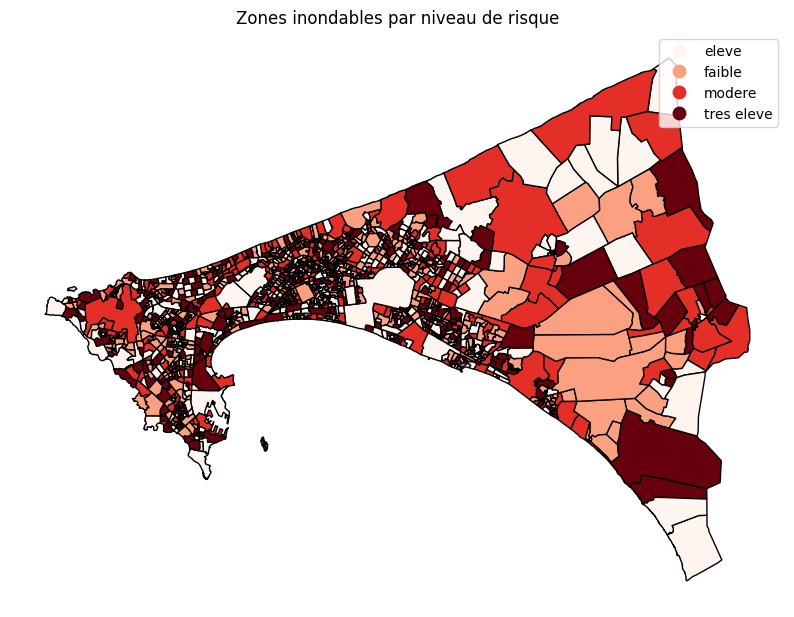

In [23]:
# Carte statique : zones colorées selon le niveau de risque (palette de rouges)
import matplotlib.pyplot as plt

gdf4.plot(
    column="niveau_risque",   # colonne qui détermine la couleur
    cmap="Reds",              # dégradé de rouges
    legend=True,
    edgecolor="black",        # contours noirs des polygones
    figsize=(10, 8),
)
plt.title("Zones inondables par niveau de risque")
plt.axis("off")               # masque les axes (coordonnées)
plt.show()

In [ ]:
# Installation des bibliothèques nécessaires aux cartes interactives
# folium : cartes web / matplotlib : graphiques / mapclassify : classification pour .explore()
%pip install folium matplotlib mapclassify

In [25]:
# Carte interactive (zoom, survol, infobulles) colorée par niveau de risque
gdf4.explore(column="niveau_risque", cmap="Reds", legend=True)

## 6. Zone tampon de 100 m autour des zones à risque très élevé

In [ ]:
# --- Zone tampon autour des zones à risque très élevé ---
gdf4 = gdf4[gdf4["niveau_risque"] == "tres eleve"]

# Tampon de 100 mètres autour de chaque zone (unité du CRS = mètre)
tampon = gdf4.copy()
tampon["geometry"] = gdf4.buffer(100)

<Axes: >

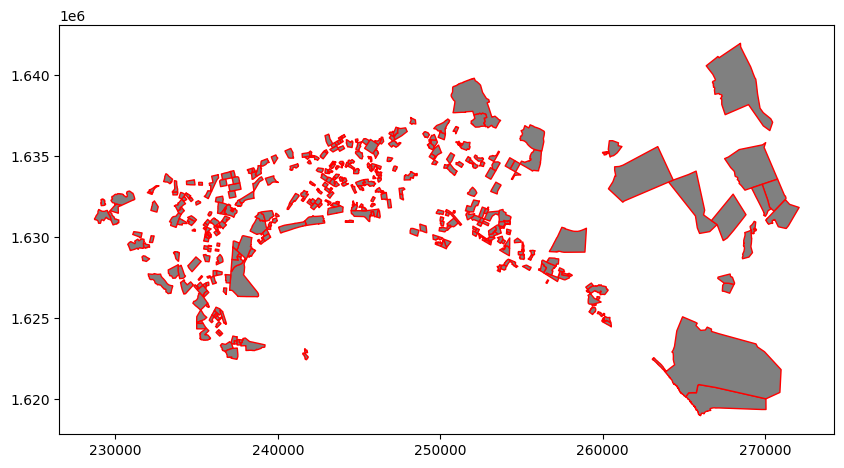

In [27]:
# "Anneau" : le tampon moins la zone elle-même, pour ne garder que la bande de 100 m autour
anneau = tampon.copy()
anneau["geometry"] = tampon.geometry.difference(gdf4.geometry.union_all())

anneau.plot(color="gray", edgecolor="red", figsize=(10, 8))

In [ ]:
# Carte interactive combinant deux couches : le tampon (rouge) et les zones (blanc, quasi transparent)
m = tampon.explore(
    color="red",
    name="Tampon 100 m",
    style_kwds={"fillOpacity": 0.5},
)

# On ajoute la 2e couche sur la même carte grâce à m=m
gdf4.explore(
    m=m,
    color="white",
    name="Zones à risque élevé",
    style_kwds={"fillOpacity": 0.1},
)

import folium
folium.LayerControl().add_to(m)   
m

## 7. Infrastructures exposées (jointure spatiale)

In [ ]:
# --- Exposition des infrastructures ---
# Jointure spatiale : on garde les infrastructures (points) situées À L'INTÉRIEUR d'une zone.
# how="inner" -> seules les infrastructures en zone inondable sont conservées.
infra_exposees = gpd.sjoin(gdf2, gdf4, how="inner", predicate="within")

print(len(infra_exposees), "infrastructures en zone inondable")
print(infra_exposees.groupby("niveau_risque").size())  

501 infrastructures en zone inondable
niveau_risque
tres eleve    501
dtype: int64


In [30]:
# Contrôle qualité : une infrastructure située dans 2 zones se retrouverait en double (résultat : 0)
print(infra_exposees.index.duplicated().sum(), "doublons")

0 doublons


In [31]:
# Part des infrastructures exposées (nunique() évite de compter deux fois la même infrastructure)
total = len(gdf2)
exposees = infra_exposees.index.nunique()

print(f"{exposees} sur {total} infrastructures exposées ({exposees / total:.1%})")

501 sur 1586 infrastructures exposées (31.6%)


In [32]:
# Rappel des colonnes de gdf2 pour repérer celle qui contient le nom
print(gdf2.columns)

Index(['id_inf', 'nom_infra', 'id_zone', 'geom'], dtype='str')


In [33]:
# Liste des infrastructures exposées avec leur commune et leur niveau de risque
nom = "nom_infra"   # nom de la colonne contenant le nom de l'infrastructure

liste = (
    infra_exposees[[nom, "commune", "niveau_risque"]]
    .sort_values("niveau_risque", ascending=False)
    .reset_index(drop=True)
)
print(liste)

               nom_infra             commune niveau_risque
0            Ecole arabe        PIKINE OUEST    tres eleve
1                Mosquée              OUAKAM    tres eleve
2                Mosquée  MERMOZ-SACRE COEUR    tres eleve
3             Terrain nu  MERMOZ-SACRE COEUR    tres eleve
4    Collège Sacré Coeur  MERMOZ-SACRE COEUR    tres eleve
..                   ...                 ...           ...
496          Gouvernance             PLATEAU    tres eleve
497           Préfecture             PLATEAU    tres eleve
498          Station ELF             PLATEAU    tres eleve
499              Parking             PLATEAU    tres eleve
500               Verger         KEUR MASSAR    tres eleve

[501 rows x 3 columns]


## 8. Classification par type et taux d'exposition

In [34]:
# --- Classification des infrastructures par type ---
# Il n'y a pas de colonne "type" dans la base : on le devine à partir du nom,
# grâce à des expressions régulières (regex) cherchant des mots-clés.
import re

# Dictionnaire {catégorie: motif regex}. [ée] accepte "é" et "e" (accents parfois absents).
regles = {
    "École":     r"[ée]cole|lyc[ée]e|coll[èe]ge|universit|cem\b",
    "Santé":     r"h[ôo]pital|clinique|poste de sant|dispensaire|maternit|centre de sant",
    "Culte":     r"mosqu[ée]e|[ée]glise|chapelle|cath[ée]drale",
    "Marché":    r"march[ée]",
    "Administration": r"mairie|pr[ée]fecture|commissariat|gendarmerie|tribunal|sous-pr[ée]fecture",
    "Eau/Énergie": r"ch[âa]teau d'eau|forage|station|senelec|sones",
}

def deviner_type(texte):
    """Retourne la catégorie dont le motif apparaît dans le nom, sinon 'Autre'."""
    if not isinstance(texte, str):   # nom vide ou non textuel
        return "Autre"
    for categorie, motif in regles.items():   # la 1re catégorie qui correspond gagne
        if re.search(motif, texte, flags=re.IGNORECASE):
            return categorie
    return "Autre"

# Applique la fonction à chaque nom pour créer la colonne "type_infra"
gdf2["type_infra"] = gdf2[nom].apply(deviner_type)

In [35]:
# Contrôle de la classification : aperçu des 40 premiers noms,
# puis liste de tout ce qui est resté en "Autre" (pour repérer des mots-clés à ajouter aux règles)
print(gdf2[nom].head(40).tolist())
print(gdf2[gdf2["type_infra"] == "Autre"][nom].tolist())   # ce qui n'a pas été classé

['CGE', "L'ESPACE", 'COSINCO', 'MICHELIN', 'UNIVERS MOTORS FORD', 'BISS CANON', "AFRICAINE DE L'AUTOMOBILE", 'SEGOF', "Station d'essence", "Station d'essence", 'Dispensaire', 'EQUIPECHE', 'Mosquée', 'Toilettes publiques', 'PAPETERIE ETOILE', 'GE CO ME', 'AGENCE  DE NAVIGATION', 'LOIX AUTOMOBILE', 'GRAND GARAGE', 'USINE CONFISERIE NOUJAIN', 'HOLYW NOUWAI', "DIRECTION GENERALE DE L'AGRICULTURE", 'LG SERVICES APRES VENTES', 'JUDO CLUB', 'SAPEC', 'SOCOSAC', 'UNIVERSAL TRANSIT', 'LACAFA', 'PFORDE ELECTRICITE', 'SORAREP', 'SAPEC PEINTURE', 'EURABAT', 'ETS I KARY', 'ECOPOLE', 'CABINE MJS', 'SOLDECO MECANICIEN', 'MECANICIEM', 'PACHA HOTEL', 'GOOD YEAV', 'Mosquée']
['CGE', "L'ESPACE", 'COSINCO', 'MICHELIN', 'UNIVERS MOTORS FORD', 'BISS CANON', "AFRICAINE DE L'AUTOMOBILE", 'SEGOF', 'EQUIPECHE', 'Toilettes publiques', 'PAPETERIE ETOILE', 'GE CO ME', 'AGENCE  DE NAVIGATION', 'LOIX AUTOMOBILE', 'GRAND GARAGE', 'USINE CONFISERIE NOUJAIN', 'HOLYW NOUWAI', "DIRECTION GENERALE DE L'AGRICULTURE", 'LG SE

In [36]:
# --- Tableau final : taux d'exposition par type d'infrastructure ---
# On recalcule la jointure car gdf2 a maintenant la colonne "type_infra"
infra_exposees = gpd.sjoin(gdf2, gdf4, how="inner", predicate="within")

col = "type_infra"
total_par_type = gdf2.groupby(col).size().rename("total")           # nb d'infrastructures par type
expo_par_type = infra_exposees.groupby(col).size().rename("exposees")  # nb d'infrastructures exposées par type

# Fusion des deux comptages ; fillna(0) pour les types sans aucune infrastructure exposée
tableau = total_par_type.to_frame().join(expo_par_type).fillna(0).astype(int)
tableau["taux_%"] = (tableau["exposees"] / tableau["total"] * 100).round(1)   # pourcentage exposé

print(tableau.sort_values("taux_%", ascending=False))

                total  exposees  taux_%
type_infra                             
Administration     17         7    41.2
Autre             945       319    33.8
École             128        40    31.2
Eau/Énergie        62        19    30.6
Culte             352        97    27.6
Marché             45        12    26.7
Santé              37         7    18.9


## Résultats

- **501 infrastructures sur 1 586 (31,6 %)** sont dans une zone à risque *très élevé*.
- Le taux d'exposition le plus fort concerne les **administrations (41,2 %)**, le plus faible la **santé (18,9 %)**.